# Credit Default Risk Prediction

## Notebook Objective

Develop a machine learning system to predict whether a borrower will default on a loan using historical credit data. The notebook covers the complete machine learning workflow, including data understanding, exploratory data analysis, data preprocessing, model development, and model evaluation.

## Data Understanding

Understand the dataset, identify the prediction target, inspect data quality, and gather the information required to define the machine learning problem before model development.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

In [2]:
# set project paths
PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
PROJECT_ROOT

WindowsPath('c:/Arshad/Projects/bits-ai-engineering/credit-default-risk-prediction')

In [3]:
# Define dataset file
# Use the second Excel row as column headers because the first row contains placeholder labels (X1, X2, ...)
DATA_FILE = RAW_DATA_DIR / "default of credit card clients.xls"
DATA_FILE

WindowsPath('c:/Arshad/Projects/bits-ai-engineering/credit-default-risk-prediction/data/raw/default of credit card clients.xls')

In [4]:
# Load dataset
df = pd.read_excel(DATA_FILE, header=1)
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [5]:
# Check dataset dimensions
df.shape

(30000, 25)

In [6]:
# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_AMT3        

In [7]:
# Display summary statistics
df.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [8]:
# Check missing values
df.isnull().sum()

ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64

In [9]:
# Check target variable distribution count
df["default payment next month"].value_counts()

default payment next month
0    23364
1     6636
Name: count, dtype: int64

In [10]:
# Check target variable distribution percentage
df["default payment next month"].value_counts(normalize=True) * 100

default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64

### Key Features

The dataset contains the following major categories of features:

- Customer information (e.g., credit limit, gender, education, marital status, age)
- Historical repayment status (PAY_0 to PAY_6)
- Previous bill statement amounts (BILL_AMT1 to BILL_AMT6)
- Previous payment amounts (PAY_AMT1 to PAY_AMT6)
- Target variable: default payment next month

In [11]:
# Summary statistics for repayment status
df[["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]].describe()

,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000
mean,-0.016700,-0.133767,-0.166200,-0.220667,-0.266200,-0.291100
std,1.123802,1.197186,1.196868,1.169139,1.133187,1.149988
min,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000
25%,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000


In [12]:
# Display repayment status distribution for PAY_0
df["PAY_0"].value_counts().sort_index()

PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

In [13]:
# Compare repayment status with default outcome
pd.crosstab(
    df["PAY_0"],
    df["default payment next month"],
    normalize="index"
) * 100

default payment next month,0,1
PAY_0,,
-2,86.770569,13.229431
-1,83.221949,16.778051
0,87.188709,12.811291
1,66.052061,33.947939
2,30.858643,69.141357
3,24.223602,75.776398
4,31.578947,68.421053
5,50.000000,50.000000
6,45.454545,54.545455


## Baseline Model

The objective of this section is to establish a simple, interpretable baseline model that can be used as a benchmark for evaluating more advanced machine learning models.

### Baseline Rule

Based on the initial analysis of repayment status, customers whose most recent repayment status (`PAY_0`) indicates a payment delay of one month or more (`PAY_0 >= 1`) exhibited a substantially higher default rate than the overall dataset. Therefore, the following rule is selected as the baseline:

> Predict **Default (1)** if `PAY_0 >= 1`; otherwise predict **No Default (0)**.

In [14]:
# Create baseline predictions
baseline_prediction = (df["PAY_0"] >= 1).astype(int)

In [15]:
# Import metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

In [16]:
# Actual target values
y_true = df["default payment next month"]

# Evaluate baseline model
baseline_accuracy = accuracy_score(y_true, baseline_prediction)
baseline_precision = precision_score(y_true, baseline_prediction)
baseline_recall = recall_score(y_true, baseline_prediction)
baseline_f1 = f1_score(y_true, baseline_prediction)

# Display results
print(f"Baseline Accuracy : {baseline_accuracy:.4f}")
print(f"Baseline Precision: {baseline_precision:.4f}")
print(f"Baseline Recall   : {baseline_recall:.4f}")
print(f"Baseline F1 Score : {baseline_f1:.4f}")

Baseline Accuracy : 0.7801
Baseline Precision: 0.5029
Baseline Recall   : 0.5167
Baseline F1 Score : 0.5097


In [17]:
# Generate confusion matrix
cm = confusion_matrix(y_true, baseline_prediction)

cm_df = pd.DataFrame(
    cm,
    index=["Actual: No Default", "Actual: Default"],
    columns=["Predicted: No Default", "Predicted: Default"]
)

cm_df

,Predicted: No Default,Predicted: Default
Actual: No Default,19975,3389
Actual: Default,3207,3429


## Data Preparation

The objective of this section is to prepare the dataset for machine learning by performing the necessary preprocessing steps. These include creating a stratified train-test split, handling missing values (if any), encoding categorical variables, scaling numerical features, and constructing a preprocessing pipeline to ensure a clean, reproducible, and consistent workflow.

### 1. Train-Test Split

In [18]:
from sklearn.model_selection import train_test_split

In [19]:
# Separate features and target
X = df.drop(columns=["default payment next month"])
y = df["default payment next month"]

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (30000, 24)
Target shape: (30000,)


In [20]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(f"Training set: {X_train.shape}")
print(f"Testing set : {X_test.shape}")

Training set: (24000, 24)
Testing set : (6000, 24)


In [21]:
# Verify class distribution after train-test split
distribution = pd.DataFrame({
    "Original Dataset": y.value_counts(normalize=True) * 100,
    "Training Set": y_train.value_counts(normalize=True) * 100,
    "Testing Set": y_test.value_counts(normalize=True) * 100
})

distribution = distribution.rename(index={
    0: "No Default",
    1: "Default"
})
distribution.index.name = None
distribution.round(2)

,Original Dataset,Training Set,Testing Set
No Default,77.88,77.88,77.88
Default,22.12,22.12,22.12


**Observation:**

The class distribution in both the training and testing sets closely matches that of the original dataset, confirming that stratified sampling successfully preserved the proportion of defaulting and non-defaulting customers. This helps ensure that model training and evaluation are performed on representative datasets.

### 2. Missing Value Handling

In [22]:
# Check for missing values
missing_values = X_train.isnull().sum()

print("Any missing values in training set?", missing_values.any())

Any missing values in training set? False


The dataset was initially inspected during the Data Understanding phase and no missing values were identified. Following the train-test split, the training dataset was verified again and contained no missing values. Therefore, no imputation step was required for this dataset before model training.

### 3. Feature Selection

In [23]:
# Remove identifier column
X_train = X_train.drop(columns=["ID"])
X_test = X_test.drop(columns=["ID"])

In [24]:
assert "ID" not in X_train.columns
assert "ID" not in X_test.columns
print(f"Training set shape after removing ID: {X_train.shape}")
print(f"Testing set shape after removing ID : {X_test.shape}")

Training set shape after removing ID: (24000, 23)
Testing set shape after removing ID : (6000, 23)


The ID field is a unique identifier and does not contain information relevant to predicting a customer's default behavior. Therefore, it was removed to eliminate an irrelevant feature before model training.

### 4. Feature Encoding

Categorical variables were reviewed to determine whether additional encoding was required before model training.

Although the features `SEX`, `EDUCATION`, and `MARRIAGE` are represented using numeric values, these values correspond to category labels rather than numerical quantities. Treating them as continuous numeric variables could introduce an artificial ordinal relationship.

Therefore, the features SEX, EDUCATION, and MARRIAGE were identified for One-Hot Encoding. The encoding will be performed as part of the preprocessing pipeline to ensure a consistent and reproducible workflow.

In [25]:
# Nominal categorical features
categorical_features = ["SEX", "EDUCATION", "MARRIAGE"]

### 5. Feature Scaling

Machine learning algorithms can be sensitive to differences in the scale of input features. In this dataset, numerical features such as credit limit, age, bill amounts, and payment amounts have substantially different value ranges. Feature scaling helps ensure that these variables contribute more consistently during model training.

Only continuous numerical features were selected for scaling. Ordinal features (`PAY_0` to `PAY_6`) were not scaled because their values represent ordered payment status categories rather than continuous measurements. Categorical features (`SEX`, `EDUCATION`, and `MARRIAGE`) will be One-Hot Encoded as part of the preprocessing pipeline and therefore are not included in the scaling step.

The selected numerical features will be standardized using `StandardScaler` within the preprocessing pipeline.

In [26]:
# Continuous numerical features
numerical_features = [
    "LIMIT_BAL",
    "AGE",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"
]

### 6. Preprocessing Pipeline

To ensure a consistent and reproducible preprocessing workflow, the identified data preparation steps were combined into a Scikit-learn preprocessing pipeline.

The pipeline performs the following operations:

- Applies One-Hot Encoding to the nominal categorical features (`SEX`, `EDUCATION`, and `MARRIAGE`).
- Applies Standard Scaling to the continuous numerical features.
- Leaves the ordinal repayment status features (`PAY_0` to `PAY_6`) unchanged.

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [28]:
# Combine all preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(drop="first", handle_unknown="ignore"),
            categorical_features,
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features,
        ),
    ],
    remainder="passthrough",
)

In [29]:
# Create preprocessing pipeline
preprocessing_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor)
    ]
)

In [30]:
preprocessing_pipeline.fit(X_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['LIMIT_BAL','SEX','EDUCATION',...,'PAY_AMT4','PAY_AMT5','PAY_AMT6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis co

In [31]:
X_train_processed = preprocessing_pipeline.transform(X_train)
X_test_processed = preprocessing_pipeline.transform(X_test)

In [32]:
print("Processed training set shape:", X_train_processed.shape)
print("Processed testing set shape :", X_test_processed.shape)

Processed training set shape: (24000, 30)
Processed testing set shape : (6000, 30)


The processed datasets (`X_train_processed` and `X_test_processed`) were created to verify that the preprocessing pipeline applies all transformations correctly. The successful transformation confirms that the pipeline is functioning as expected and is ready to be integrated with machine learning models in the subsequent stages.

## ML Model Training and Analysis

### Train a Logistic Regression Model

In [33]:
from sklearn.linear_model import LogisticRegression

In [34]:
# Create a machine learning pipeline
model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(random_state=42))
    ]
)

In [35]:
# Train the Logistic Regression model
model_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['LIMIT_BAL','SEX','EDUCATION',...,'PAY_AMT4','PAY_AMT5','PAY_AMT6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

### Model Performance Evaluation

In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [37]:
# Generate predictions on the testing set
y_pred = model_pipeline.predict(X_test)

In [38]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

In [39]:
metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Value": [accuracy, precision, recall, f1]
})

metrics["Value"] = metrics["Value"].round(4)

metrics

,Metric,Value
0,Accuracy,0.8095
1,Precision,0.6966
2,Recall,0.2457
3,F1-score,0.3632


Compared to the earlier rule-based baseline, the Logistic Regression model achieved higher Accuracy and Precision but a substantially lower Recall and F1-score. This indicates that the model became more conservative in predicting defaults, correctly identifying fewer actual defaulters while reducing false positive predictions.

### Confusion Matrix Analysis

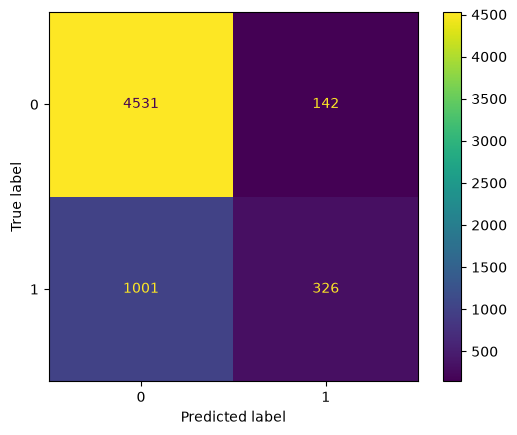

In [40]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm).plot()

The confusion matrix shows that the Logistic Regression model correctly classified most non-default cases but missed a considerable number of actual defaulters. This explains the model's high Accuracy and Precision but relatively low Recall, indicating that it is conservative when predicting the default class.

### Discussion

The dataset is imbalanced, with approximately 78% non-default cases and 22% default cases. In such datasets, Accuracy alone may not provide a complete picture of model performance because a model can achieve high Accuracy while failing to correctly identify many default cases.

For credit default prediction, **Recall** is often more important than Precision because failing to identify an actual defaulter (False Negative) can result in significant financial losses for the lender. Although the Logistic Regression model achieved good Accuracy and Precision, its relatively low Recall indicates that many actual defaulters were missed. Therefore, improving Recall should be a key objective when developing future models.

## Threshold Trade-off Analysis

The default classification threshold of Logistic Regression is 0.5, meaning observations with a predicted probability of 0.5 or higher are classified as defaulters. However, the threshold can be adjusted depending on business requirements. Lowering the threshold generally increases Recall but may reduce Precision, while increasing the threshold typically improves Precision at the expense of Recall.

This section compares the model's performance at thresholds of **0.3**, **0.5**, and **0.7**.

In [41]:
# Predict probability of default
y_prob = model_pipeline.predict_proba(X_test)[:, 1]

In [42]:
thresholds = [0.3, 0.5, 0.7]

results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, y_pred_threshold),
        "Recall": recall_score(y_test, y_pred_threshold)
    })

threshold_results = pd.DataFrame(results)
threshold_results = threshold_results.round(4)

threshold_results

,Threshold,Precision,Recall
0,0.3,0.5517,0.4582
1,0.5,0.6966,0.2457
2,0.7,0.7416,0.0497


The results demonstrate the trade-off between Precision and Recall as the classification threshold changes. Lowering the threshold from 0.5 to 0.3 increases Recall from 24.57% to 45.82%, allowing the model to identify a larger proportion of actual defaulters. However, this comes at the cost of lower Precision. Increasing the threshold to 0.7 improves Precision but drastically reduces Recall, causing many actual defaulters to be missed.

Since missing a customer who is likely to default can result in significant financial losses, a threshold of **0.3** provides a better balance for this credit risk prediction problem. Although it generates more false alarms, it identifies substantially more defaulters, helping reduce the financial risk associated with missed defaults.

## Error Analysis

To better understand the model's limitations, we analyze the False Negative predictions. These are customers who actually defaulted but were incorrectly predicted as non-defaulters. Identifying common characteristics among these cases can help improve future models.

In [43]:
false_negatives = X_test[
    (y_test == 1) &
    (y_pred == 0)
]

In [44]:
false_negatives.describe()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
count,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000,...,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000
mean,154283.396603,1.587413,1.900100,1.532468,35.837163,0.088911,-0.063936,-0.166833,-0.244755,-0.242757,...,48274.229770,43753.151848,40690.884116,39346.953047,3750.534466,3809.016983,3407.728272,3196.207792,3128.354645,3782.331668
std,125843.173627,0.492546,0.741627,0.518840,9.534593,1.120307,1.289926,1.251854,1.237350,1.232887,...,81451.215462,72751.426629,68597.526528,67203.595827,8447.696616,12756.456996,9499.305256,9939.620638,8290.064441,12639.139085
min,10000.000000,1.000000,1.000000,1.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-46127.000000,-65167.000000,-53007.000000,-94625.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,780.000000,632.000000,430.000000,390.000000,0.000000,109.000000,0.000000,0.000000,0.000000,0.000000
50%,120000.000000,2.000000,2.000000,2.000000,35.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,16236.000000,16166.000000,13295.000000,11487.000000,1600.000000,1600.000000,1200.000000,1000.000000,1001.000000,1000.000000
75%,230000.000000,2.000000,2.000000,2.000000,42.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,53377.000000,49423.000000,46564.000000,47369.000000,3856.000000,3823.000000,3427.000000,3000.000000,3076.000000,3053.000000
max,600000.000000,2.000000,6.000000,3.000000,73.000000,2.000000,4.000000,4.000000,4.000000,7.000000,...,578971.000000,493548.000000,447130.000000,440982.000000,125000.000000,302000.000000,179460.000000,159658.000000,107591.000000,196000.000000


In [45]:
false_negatives["SEX"].value_counts()

SEX
2    588
1    413
Name: count, dtype: int64

In [46]:
false_negatives["EDUCATION"].value_counts()

EDUCATION
2    483
1    314
3    199
5      3
6      1
4      1
Name: count, dtype: int64

In [47]:
false_negatives["MARRIAGE"].value_counts()

MARRIAGE
2    513
1    478
3     10
Name: count, dtype: int64

In [48]:
false_negatives["PAY_0"].value_counts()

PAY_0
 0    380
 1    206
-1    201
 2    128
-2     86
Name: count, dtype: int64

In [49]:
false_negatives[["LIMIT_BAL", "AGE", "PAY_0"]].describe()

,LIMIT_BAL,AGE,PAY_0
count,1001.000000,1001.000000,1001.000000
mean,154283.396603,35.837163,0.088911
std,125843.173627,9.534593,1.120307
min,10000.000000,21.000000,-2.000000
25%,50000.000000,28.000000,-1.000000
50%,120000.000000,35.000000,0.000000
75%,230000.000000,42.000000,1.000000
max,600000.000000,73.000000,2.000000


**Key Insights**

1. The model produced **1,001 False Negative predictions**, indicating that a considerable number of actual defaulters were missed.

2. Most False Negatives had **PAY_0 values between -1 and 1**, with the largest group having a repayment status of **0**. This suggests that the model had greater difficulty identifying customers with little or no recent repayment delay.

3. The median credit limit and age of the False Negative group were **120,000** and **35 years**, respectively. This indicates that missed defaulters were generally customers with moderate credit limits and typical working-age profiles rather than extreme cases.

4. False Negatives were observed across different genders, education levels, and marital status categories, suggesting that the errors were distributed across multiple customer groups rather than being concentrated in a single category.

## Production Considerations

Once a machine learning model is deployed, it receives new customer data and generates predictions in a production environment. To ensure reliable performance, the input data must be validated, the model should be continuously monitored, and it should be retrained whenever significant changes occur in the data or model performance.

### Input Schema

| Field | Data Type |
|---------|-----------|
| LIMIT_BAL | Integer |
| SEX | Integer |
| EDUCATION | Integer |
| MARRIAGE | Integer |
| AGE | Integer |
| PAY_0 to PAY_6 | Integer |
| BILL_AMT1 to BILL_AMT6 | Integer |
| PAY_AMT1 to PAY_AMT6 | Integer |

### Input Validation

**If the LIMIT_BAL column is missing**

The model cannot generate predictions because a required input feature is unavailable. The request should be rejected or the missing value should be imputed before prediction.

**If an unseen category appears**

The pipeline uses `OneHotEncoder(handle_unknown="ignore")`. Therefore, unseen categorical values will be ignored during encoding, allowing the model to continue making predictions without failing.

### Production Monitoring

The following aspects should be monitored after deployment:

- Data drift (for example, changes in the distribution of credit limits or repayment behavior).
- Percentage of customers predicted as defaulters.
- Precision and Recall of the model when actual outcomes become available.
- Number of False Positive and False Negative predictions.
- Input data quality, including missing values and unexpected feature values.

### Retraining Strategy

The model should be retrained when significant data drift is detected or when model performance drops below an acceptable level. Retraining may also be required if business rules change or when a sufficient amount of new customer data becomes available.

## Addressing Class Imbalance

The original Logistic Regression model was trained without considering class imbalance. In this experiment, the model is retrained using `class_weight="balanced"`, which assigns higher importance to the minority (default) class during training. The objective is to evaluate whether this improves the model's ability to identify default cases.

In [50]:
# Train the model
balanced_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)

balanced_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['LIMIT_BAL','SEX','EDUCATION',...,'PAY_AMT4','PAY_AMT5','PAY_AMT6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

In [51]:
# Predict
balanced_pred = balanced_pipeline.predict(X_test)

In [52]:
balanced_accuracy = accuracy_score(y_test, balanced_pred)
balanced_precision = precision_score(y_test, balanced_pred)
balanced_recall = recall_score(y_test, balanced_pred)
balanced_f1 = f1_score(y_test, balanced_pred)

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Original": [
        accuracy,
        precision,
        recall,
        f1
    ],
    "Balanced": [
        balanced_accuracy,
        balanced_precision,
        balanced_recall,
        balanced_f1
    ]
})

comparison = comparison.round(4)

comparison

,Metric,Original,Balanced
0,Accuracy,0.8095,0.6780
1,Precision,0.6966,0.3674
2,Recall,0.2457,0.6315
3,F1-score,0.3632,0.4645


Using `class_weight="balanced"` significantly improved the model's ability to identify default cases. Recall increased from **24.57%** to **63.15%**, and the F1-score also improved from **0.3632** to **0.4645**. However, this came at the cost of lower Accuracy and Precision, indicating that the model generated more false positive predictions.

This trade-off may be acceptable for credit risk prediction because failing to identify an actual defaulter is generally more costly than investigating additional customers who are incorrectly flagged as high risk.